In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.cluster import KMeans
from sklearn.metrics import mean_squared_error, r2_score, classification_report, confusion_matrix
from sklearn.preprocessing import StandardScaler

import warnings
warnings.filterwarnings("ignore")

plt.style.use("default")
sns.set_palette("husl")

print("="*70)
print("ENERGY CONSUMPTION AND EFFICIENCY ANALYSIS PROJECT")
print("="*70)


ENERGY CONSUMPTION AND EFFICIENCY ANALYSIS PROJECT


In [2]:
# If running in Google Colab, this opens a file picker to upload the CSV.
# If running locally (e.g. from this repo's data/ folder), it's skipped automatically.
try:
    from google.colab import files
    uploaded = files.upload()
except ImportError:
    print("Not running in Colab - skipping upload, will read from the local data/ folder instead.")

Not running in Colab - skipping upload, will read from the local data/ folder instead.


In [3]:
import pandas as pd
import os

csv_path = "Household energy unit data.csv" if os.path.exists("Household energy unit data.csv") else "data/household_energy_unit_data.csv"
df = pd.read_csv(csv_path)
print("Dataset Shape:", df.shape)
print(df.head())

Dataset Shape: (1000, 9)
   num_rooms  num_people  housearea  is_ac  is_tv  is_flat  num_children  \
0          3           3     742.57      1      1        1             2   
1          1           5     952.99      0      1        0             1   
2          3           1     761.44      1      1        1             0   
3          0           5     861.32      1      1        0             0   
4          1           8     731.61      0      1        0             2   

   is_urban       units  
0         0  134.731117  
1         1  125.315527  
2         0  123.047874  
3         0   80.046162  
4         1  128.429094  


In [4]:
# ============================================================
# STEP 2: FEATURE ENGINEERING
# ============================================================
print("\nSTEP 2: FEATURE ENGINEERING")
print("-"*50)

# 1. Total Energy Consumption
#    Why? This column represents the total energy consumed by each household in kWh.
#    Useful for direct regression (predicting energy usage) and for cost calculation if tariff is given.
df["Total_Energy_kWh"] = df["units"]


STEP 2: FEATURE ENGINEERING
--------------------------------------------------


In [5]:
# 2. Energy Consumption per Person
#    Why? Normalizes total consumption by household size.
#    Helps identify efficiency on a per-person basis and is great for classification (efficient vs inefficient).
df["Energy_per_Person"] = df["units"] / df["num_people"].replace(0, 1)


In [6]:
# 3. Energy Intensity (kWh per square meter)
#    Why? Normalizes energy use by house area.
#    Useful for clustering and comparing large vs small houses fairly.
df["Energy_per_SqM"] = df["units"] / df["housearea"]

In [7]:
print("\nFirst 5 rows:")
print(df.head())


First 5 rows:
   num_rooms  num_people  housearea  is_ac  is_tv  is_flat  num_children  \
0          3           3     742.57      1      1        1             2   
1          1           5     952.99      0      1        0             1   
2          3           1     761.44      1      1        1             0   
3          0           5     861.32      1      1        0             0   
4          1           8     731.61      0      1        0             2   

   is_urban       units  Total_Energy_kWh  Energy_per_Person  Energy_per_SqM  
0         0  134.731117        134.731117          44.910372        0.181439  
1         1  125.315527        125.315527          25.063105        0.131497  
2         0  123.047874        123.047874         123.047874        0.161599  
3         0   80.046162         80.046162          16.009232        0.092934  
4         1  128.429094        128.429094          16.053637        0.175543  


In [8]:
duplicates = df[df.duplicated()]
print("Duplicate rows:\n", duplicates)


Duplicate rows:
 Empty DataFrame
Columns: [num_rooms, num_people, housearea, is_ac, is_tv, is_flat, num_children, is_urban, units, Total_Energy_kWh, Energy_per_Person, Energy_per_SqM]
Index: []


In [9]:
print("\nDataset Info:")
print(df.info())


Dataset Info:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 12 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   num_rooms          1000 non-null   int64  
 1   num_people         1000 non-null   int64  
 2   housearea          1000 non-null   float64
 3   is_ac              1000 non-null   int64  
 4   is_tv              1000 non-null   int64  
 5   is_flat            1000 non-null   int64  
 6   num_children       1000 non-null   int64  
 7   is_urban           1000 non-null   int64  
 8   units              1000 non-null   float64
 9   Total_Energy_kWh   1000 non-null   float64
 10  Energy_per_Person  1000 non-null   float64
 11  Energy_per_SqM     1000 non-null   float64
dtypes: float64(5), int64(7)
memory usage: 93.9 KB
None


In [10]:
print("\nBasic Statistics:")
print(df.describe())



Basic Statistics:
         num_rooms   num_people    housearea        is_ac        is_tv  \
count  1000.000000  1000.000000  1000.000000  1000.000000  1000.000000   
mean      1.962000     4.897000   794.703420     0.376000     0.798000   
std       1.030348     2.007591   147.771736     0.484622     0.401693   
min      -1.000000    -1.000000   244.400000     0.000000     0.000000   
25%       1.000000     4.000000   691.037500     0.000000     1.000000   
50%       2.000000     5.000000   789.970000     0.000000     1.000000   
75%       3.000000     6.000000   892.955000     1.000000     1.000000   
max       5.000000    11.000000  1189.120000     1.000000     1.000000   

           is_flat  num_children     is_urban        units  Total_Energy_kWh  \
count  1000.000000   1000.000000  1000.000000  1000.000000       1000.000000   
mean      0.477000      1.078000     0.608000   123.597217        123.597217   
std       0.499721      0.934232     0.488441    27.106187         27.1061

In [11]:
# ============================================================
# STEP 3: DATA VISUALIZATION (BEFORE PREPROCESSING)
# ============================================================
print("\nSTEP 3: DATA VISUALIZATION (BEFORE PREPROCESSING)")
print("-"*50)

# Separate categorical and numerical columns
cat_cols = df.select_dtypes(include=["object", "category"]).columns
num_cols = df.select_dtypes(include=["int64", "float64"]).columns



STEP 3: DATA VISUALIZATION (BEFORE PREPROCESSING)
--------------------------------------------------


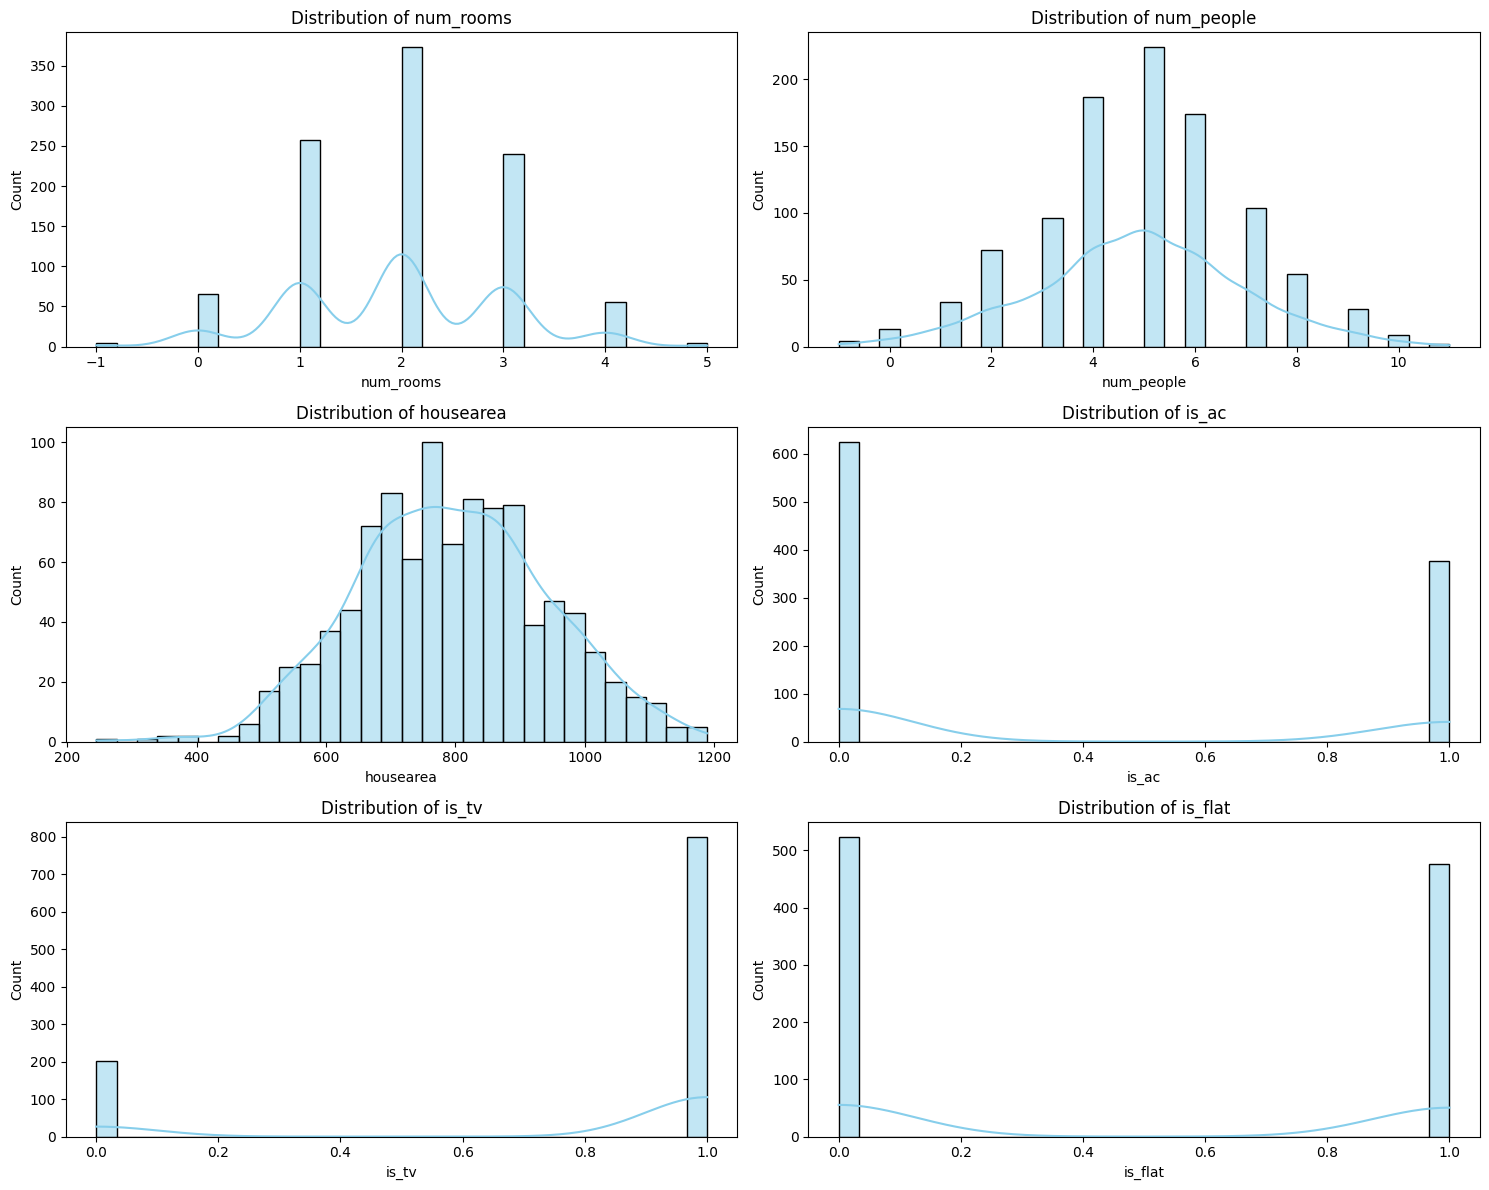

In [12]:
# --- Numerical Data Visualization ---
# 1. Histograms + KDE
plt.figure(figsize=(15, 12))
for i, col in enumerate(num_cols[:6], 1):
    plt.subplot(3, 2, i)
    sns.histplot(df[col], kde=True, bins=30, color="skyblue")
    plt.title(f"Distribution of {col}")
plt.tight_layout()
plt.show()

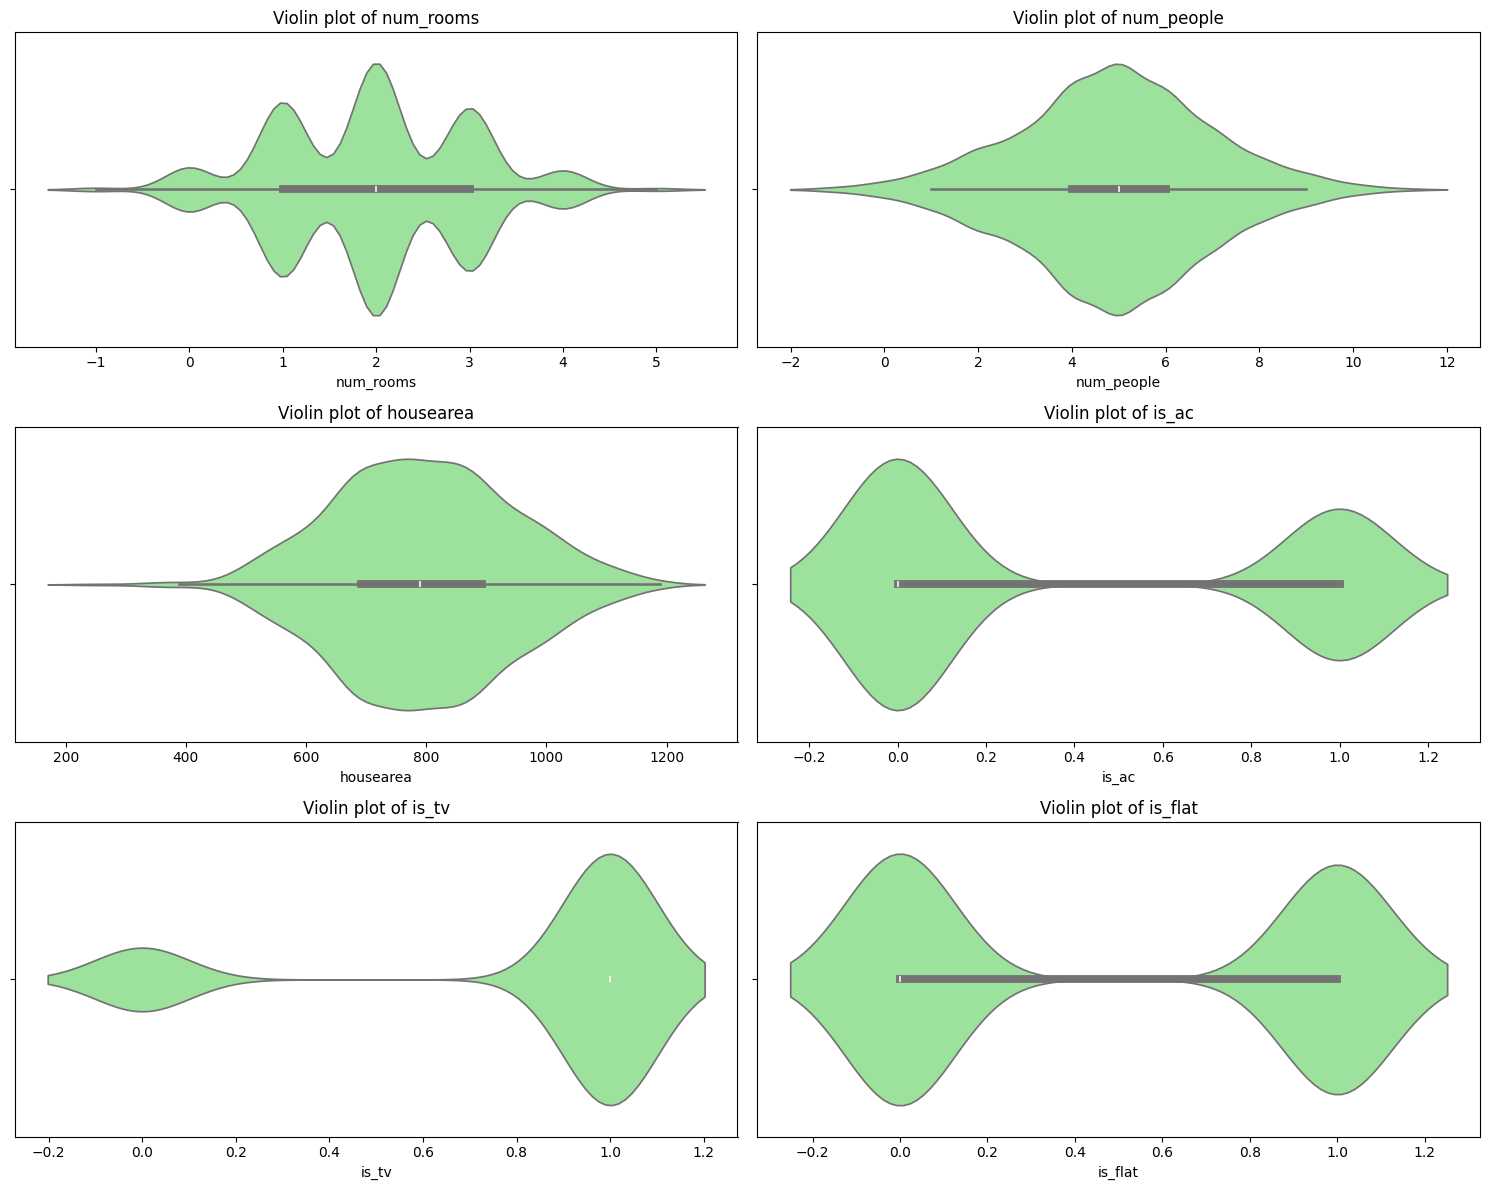

In [13]:
# 3. Violin plots (distribution + density)
plt.figure(figsize=(15, 12))
for i, col in enumerate(num_cols[:6], 1):
    plt.subplot(3, 2, i)
    sns.violinplot(x=df[col], color="lightgreen")
    plt.title(f"Violin plot of {col}")
plt.tight_layout()
plt.show()

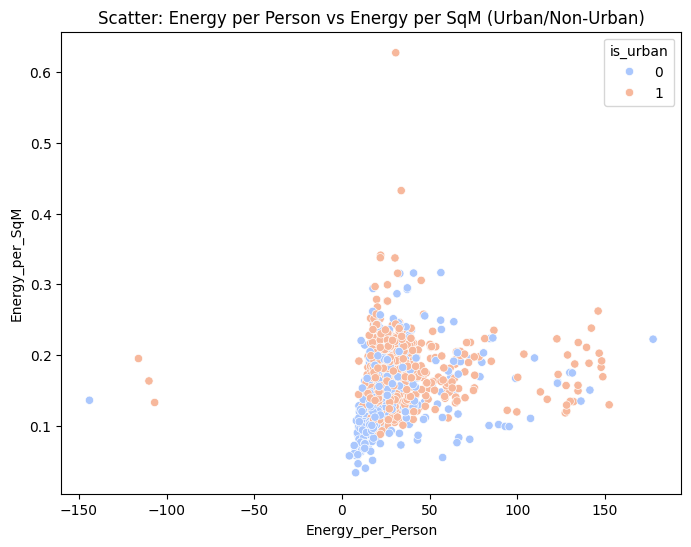

In [14]:
# 4. Scatter plots
plt.figure(figsize=(8, 6))
sns.scatterplot(x="Energy_per_Person", y="Energy_per_SqM", data=df, hue="is_urban", palette="coolwarm")
plt.title("Scatter: Energy per Person vs Energy per SqM (Urban/Non-Urban)")
plt.show()

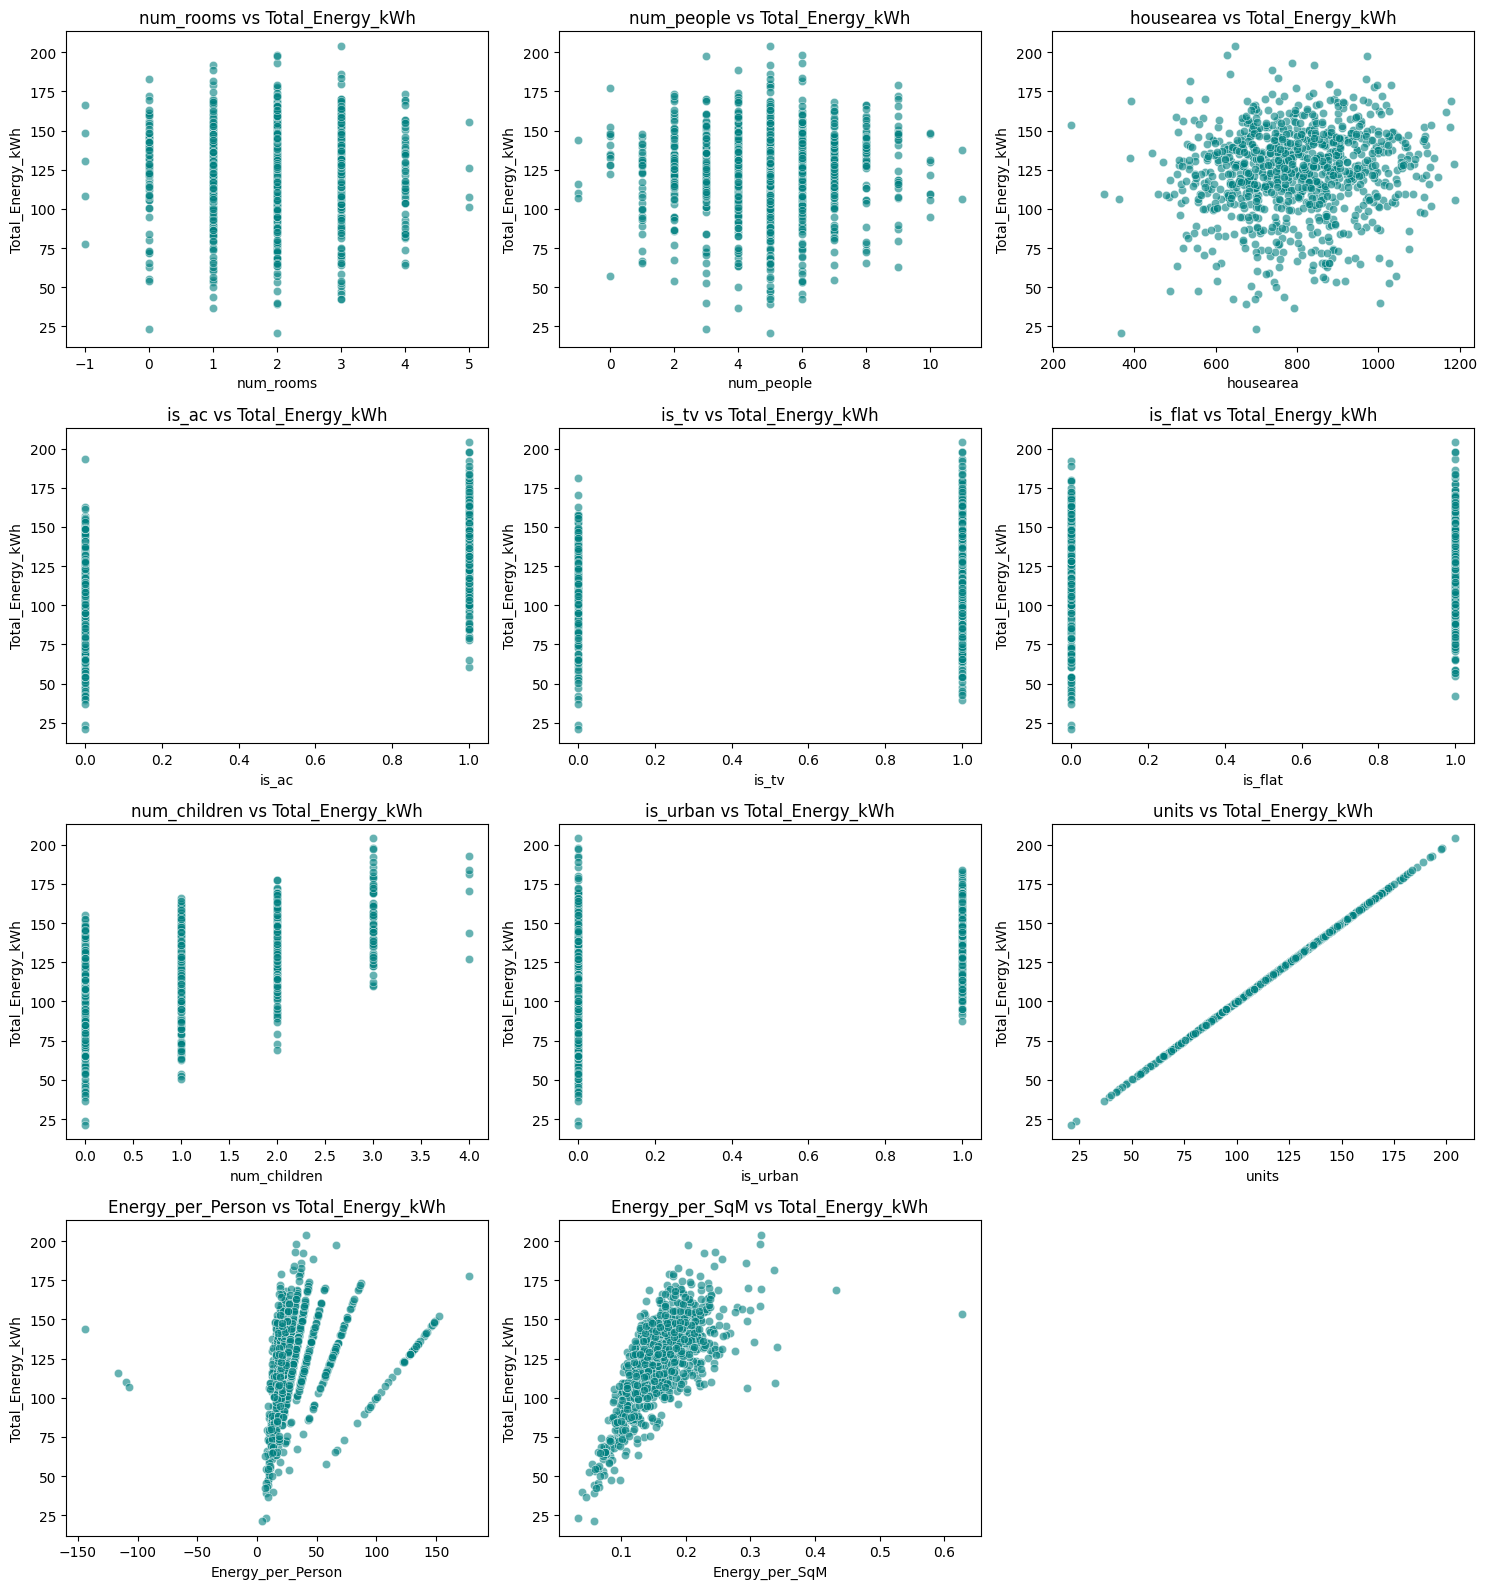

In [15]:
target = "Total_Energy_kWh"   # change if needed

plot_cols = [c for c in num_cols if c != target]
ncols = 3
nrows = int(np.ceil(len(plot_cols) / ncols))

plt.figure(figsize=(15, 4 * nrows))
for i, col in enumerate(plot_cols, 1):
    plt.subplot(nrows, ncols, i)
    sns.scatterplot(x=df[col], y=df[target], alpha=0.6, color="teal")
    plt.title(f"{col} vs {target}")
plt.tight_layout()
plt.show()

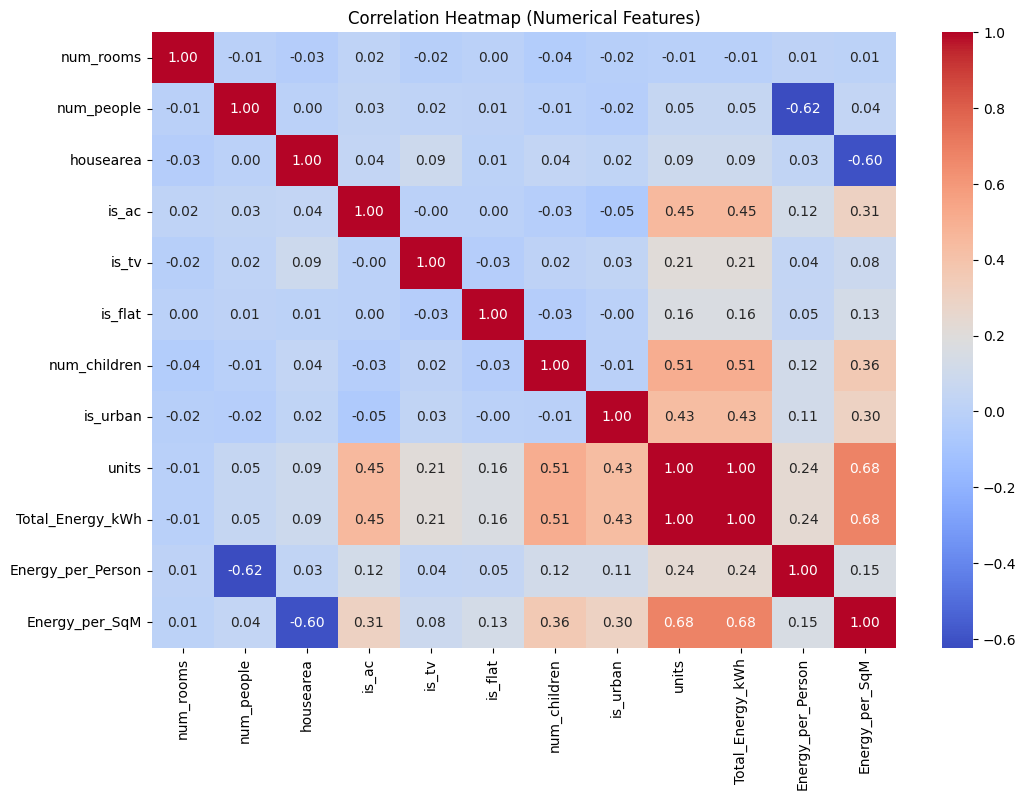

In [16]:
# 5. Correlation heatmap
plt.figure(figsize=(12, 8))
sns.heatmap(df[num_cols].corr(), annot=True, cmap="coolwarm", fmt=".2f")
plt.title("Correlation Heatmap (Numerical Features)")
plt.show()

In [17]:
# --- Categorical Data Visualization ---
for col in cat_cols:
    plt.figure(figsize=(6, 4))
    sns.countplot(x=df[col], palette="muted")
    plt.title(f"Count plot of {col}")
    plt.show()

    plt.figure(figsize=(6, 4))
    df[col].value_counts().plot.pie(autopct="%1.1f%%", colors=sns.color_palette("pastel"))
    plt.title(f"Pie Chart of {col}")
    plt.ylabel("")
    plt.show()

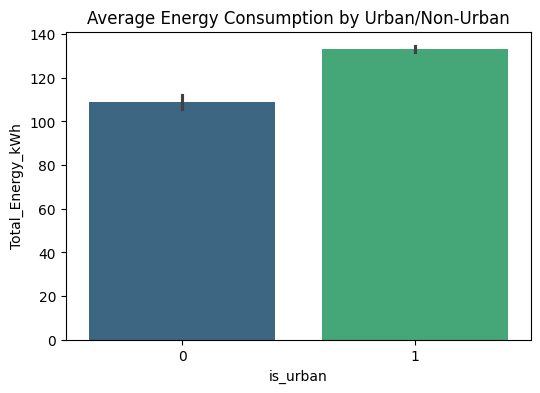

In [18]:
# Grouped bar: Average energy consumption by urban/rural
plt.figure(figsize=(6, 4))
sns.barplot(x="is_urban", y="Total_Energy_kWh", data=df, estimator=np.mean, palette="viridis")
plt.title("Average Energy Consumption by Urban/Non-Urban")
plt.show()

In [19]:
print("\n STEP 2: DATA PREPROCESSING")
print("-" * 40)


 STEP 2: DATA PREPROCESSING
----------------------------------------


In [20]:
# Check for missing values
print("Missing values per column:")
print(df.isnull().sum())




Missing values per column:
num_rooms            0
num_people           0
housearea            0
is_ac                0
is_tv                0
is_flat              0
num_children         0
is_urban             0
units                0
Total_Energy_kWh     0
Energy_per_Person    0
Energy_per_SqM       0
dtype: int64


In [21]:
# Handle missing values (if any)
for col in df.columns:
    if df[col].dtype in ["float64", "int64"]:
        df[col].fillna(df[col].median(), inplace=True)
    else:
        df[col].fillna(df[col].mode()[0], inplace=True)

print("Data preprocessing completed!")

Data preprocessing completed!


In [22]:
num_cols = df.select_dtypes(include=['int64', 'float64']).columns
print("\nShape before handling outliers:", df.shape)


Shape before handling outliers: (1000, 12)



STEP 5: VISUALIZATION BEFORE OUTLIER REMOVAL
--------------------------------------------------


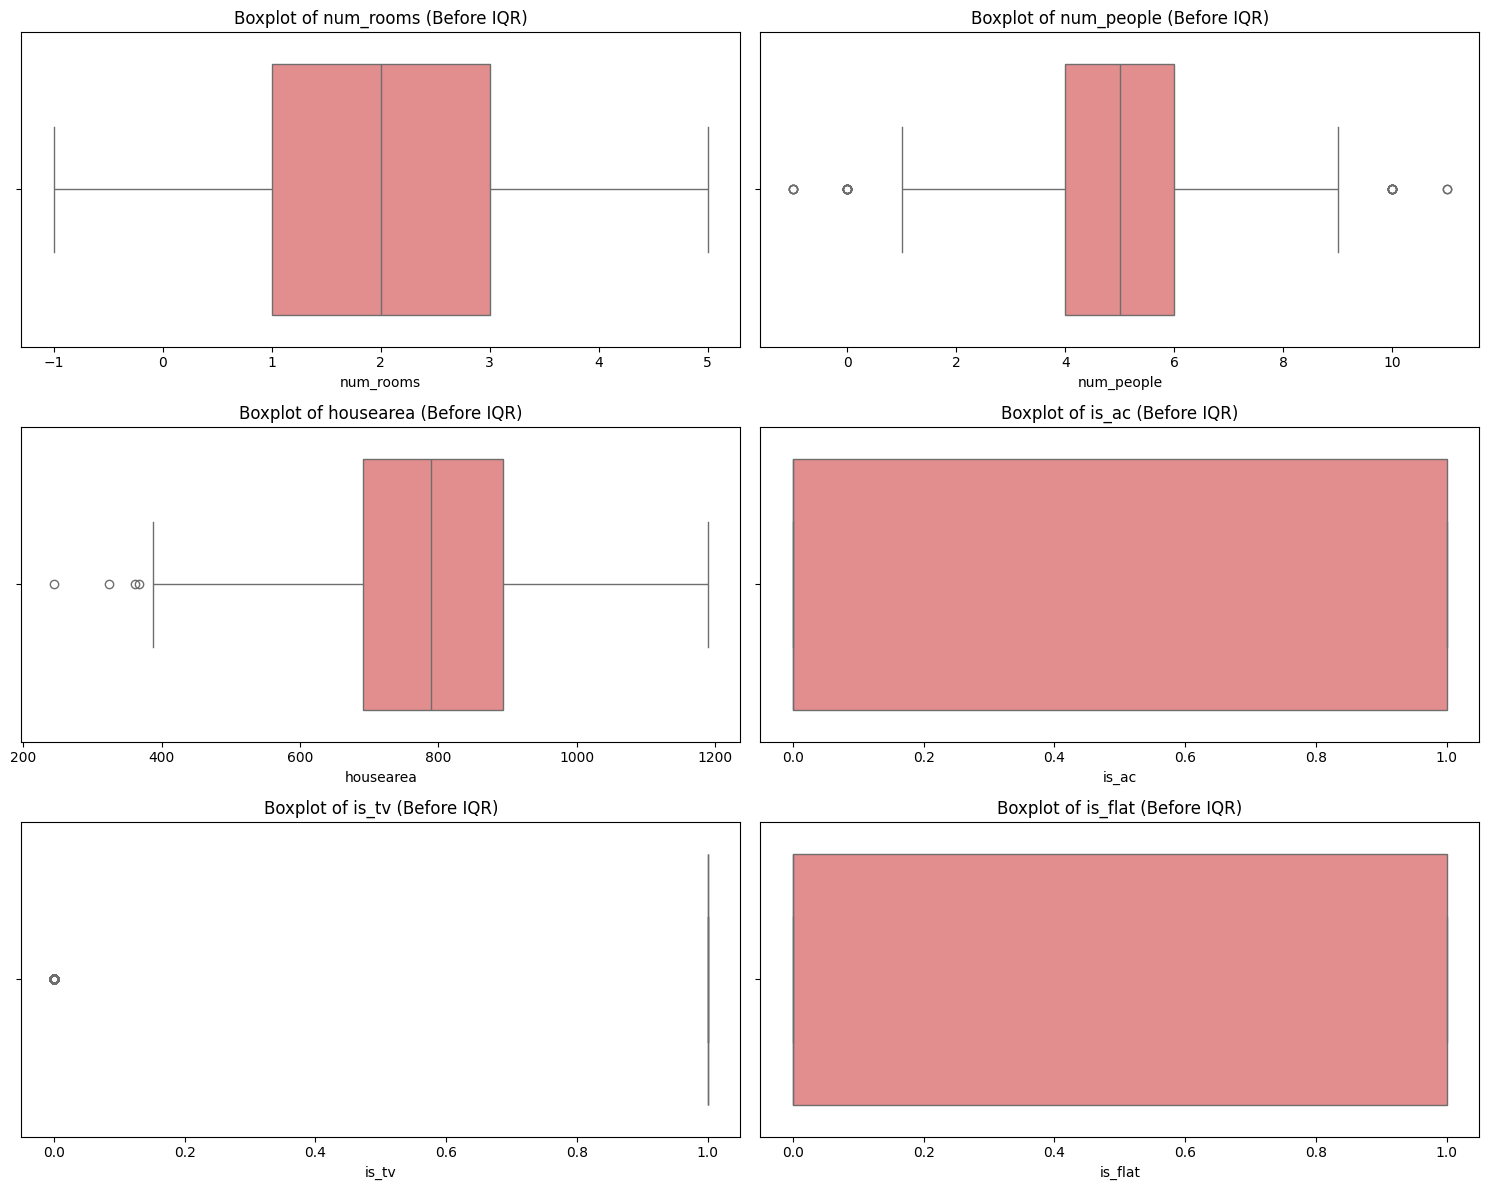

In [23]:
print("\nSTEP 5: VISUALIZATION BEFORE OUTLIER REMOVAL")
print("-"*50)

plt.figure(figsize=(15, 12))
for i, col in enumerate(num_cols[:6], 1):
    plt.subplot(3, 2, i)
    sns.boxplot(x=df[col], color="lightcoral")
    plt.title(f"Boxplot of {col} (Before IQR)")
plt.tight_layout()
plt.show()

In [24]:
# ============================================================
# STEP 6: OUTLIER REMOVAL (IQR METHOD)
# ============================================================
print("\nSTEP 6: OUTLIER REMOVAL USING IQR")
print("-"*50)

Q1 = df[num_cols].quantile(0.25)
Q3 = df[num_cols].quantile(0.75)
IQR = Q3 - Q1

df_clean = df[~((df[num_cols] < (Q1 - 1.5 * IQR)) | (df[num_cols] > (Q3 + 1.5 * IQR))).any(axis=1)]

print("Shape before outlier removal:", df.shape)
print("Shape after outlier removal:", df_clean.shape)


STEP 6: OUTLIER REMOVAL USING IQR
--------------------------------------------------
Shape before outlier removal: (1000, 12)
Shape after outlier removal: (685, 12)



STEP 7: VISUALIZATION AFTER OUTLIER REMOVAL
--------------------------------------------------


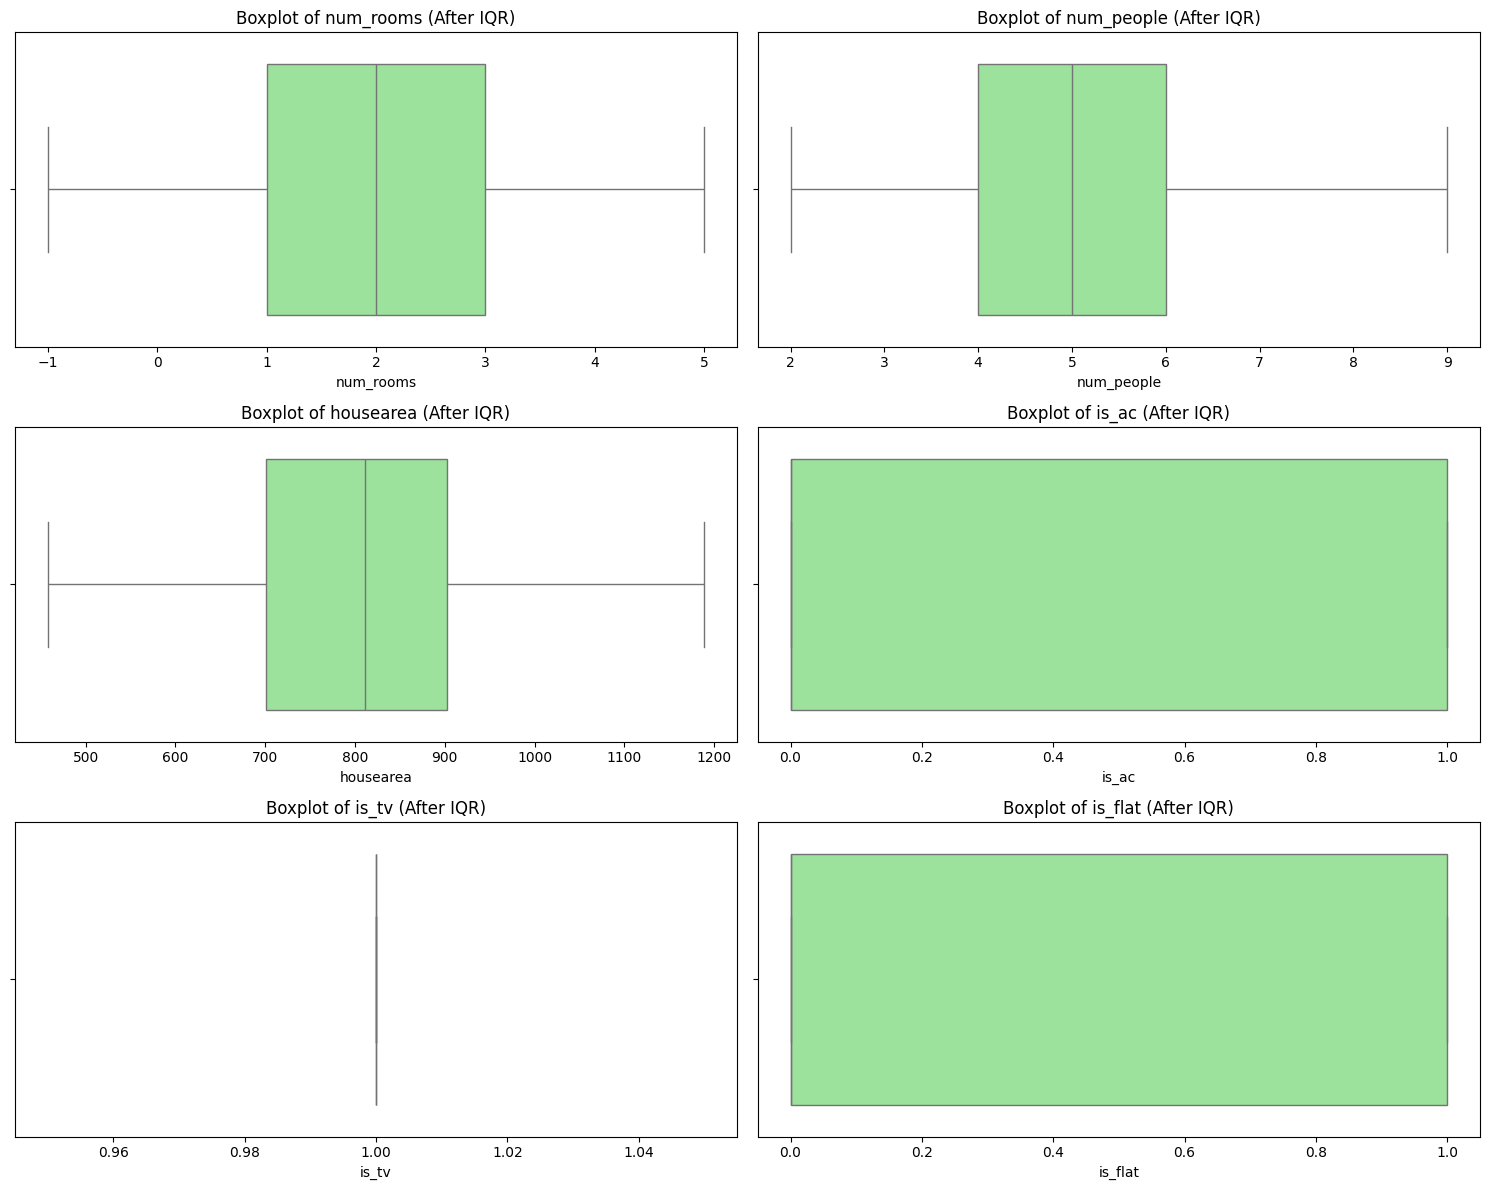

In [25]:
# ============================================================
# STEP 7: VISUALIZATION AFTER OUTLIER REMOVAL
# ============================================================
print("\nSTEP 7: VISUALIZATION AFTER OUTLIER REMOVAL")
print("-"*50)

plt.figure(figsize=(15, 12))
for i, col in enumerate(num_cols[:6], 1):
    plt.subplot(3, 2, i)
    sns.boxplot(x=df_clean[col], color="lightgreen")
    plt.title(f"Boxplot of {col} (After IQR)")
plt.tight_layout()
plt.show()

In [26]:
print("\n" + "="*70)
print("PART 2: REGRESSION - PREDICTING TOTAL ENERGY CONSUMPTION")
print("="*70)


PART 2: REGRESSION - PREDICTING TOTAL ENERGY CONSUMPTION


In [27]:
# Regression target: Total_Energy_kWh (same values as "units").
# Features: only the raw household attributes known before any energy is measured.
# Energy_per_Person and Energy_per_SqM are deliberately excluded - they are derived
# directly from the target, so including them would leak the answer into the model.
regression_features = ['num_rooms', 'num_people', 'housearea', 'is_ac', 'is_tv',
                        'is_flat', 'num_children', 'is_urban']

X = df_clean[regression_features]
y = df_clean['Total_Energy_kWh']

print(f"Regression dataset shape: {X.shape}")

Regression dataset shape: (685, 8)


In [28]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
print(f"Train size: {X_train.shape[0]}, Test size: {X_test.shape[0]}")

Train size: 548, Test size: 137


In [29]:
from sklearn.ensemble import RandomForestRegressor

# Train two models so we can compare a simple linear baseline against a
# non-linear model, instead of assuming linear regression is good enough.
lr_model = LinearRegression()
lr_model.fit(X_train, y_train)
y_pred_lr = lr_model.predict(X_test)

rf_reg_model = RandomForestRegressor(n_estimators=200, random_state=42)
rf_reg_model.fit(X_train, y_train)
y_pred_rf = rf_reg_model.predict(X_test)

In [30]:
def regression_report(name, y_true, y_pred):
    mse = mean_squared_error(y_true, y_pred)
    rmse = np.sqrt(mse)
    r2 = r2_score(y_true, y_pred)
    print(f"\n{name} RESULTS:")
    print(f"  RMSE: {rmse:.2f} kWh")
    print(f"  R² Score: {r2:.4f}")
    return {"rmse": rmse, "r2": r2}

print("U0001F4CA REGRESSION RESULTS:")
lr_metrics = regression_report("Linear Regression", y_test, y_pred_lr)
rf_metrics = regression_report("Random Forest Regressor", y_test, y_pred_rf)

# Carry forward whichever model scored higher R² for the plots below.
if rf_metrics["r2"] >= lr_metrics["r2"]:
    best_reg_name, best_reg_model, y_pred = "Random Forest Regressor", rf_reg_model, y_pred_rf
    r2, rmse = rf_metrics["r2"], rf_metrics["rmse"]
else:
    best_reg_name, best_reg_model, y_pred = "Linear Regression", lr_model, y_pred_lr
    r2, rmse = lr_metrics["r2"], lr_metrics["rmse"]

print(f"\nBest model: {best_reg_name} (R² = {r2:.4f})")

U0001F4CA REGRESSION RESULTS:

Linear Regression RESULTS:
  RMSE: 12.01 kWh
  R² Score: 0.7377

Random Forest Regressor RESULTS:
  RMSE: 13.04 kWh
  R² Score: 0.6907

Best model: Linear Regression (R² = 0.7377)


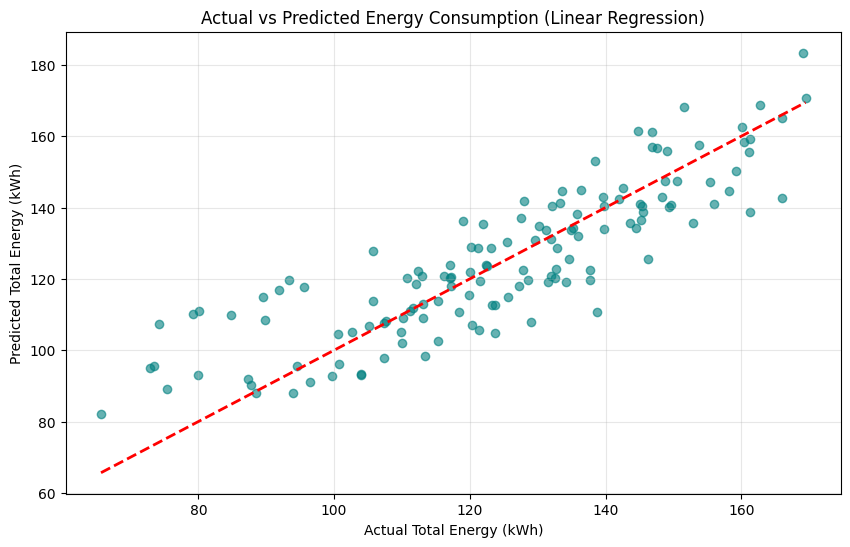

In [31]:
plt.figure(figsize=(10, 6))
plt.scatter(y_test, y_pred, alpha=0.6, color='teal')
plt.plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], 'r--', linewidth=2)
plt.xlabel('Actual Total Energy (kWh)')
plt.ylabel('Predicted Total Energy (kWh)')
plt.title(f'Actual vs Predicted Energy Consumption ({best_reg_name})')
plt.grid(True, alpha=0.3)
plt.show()

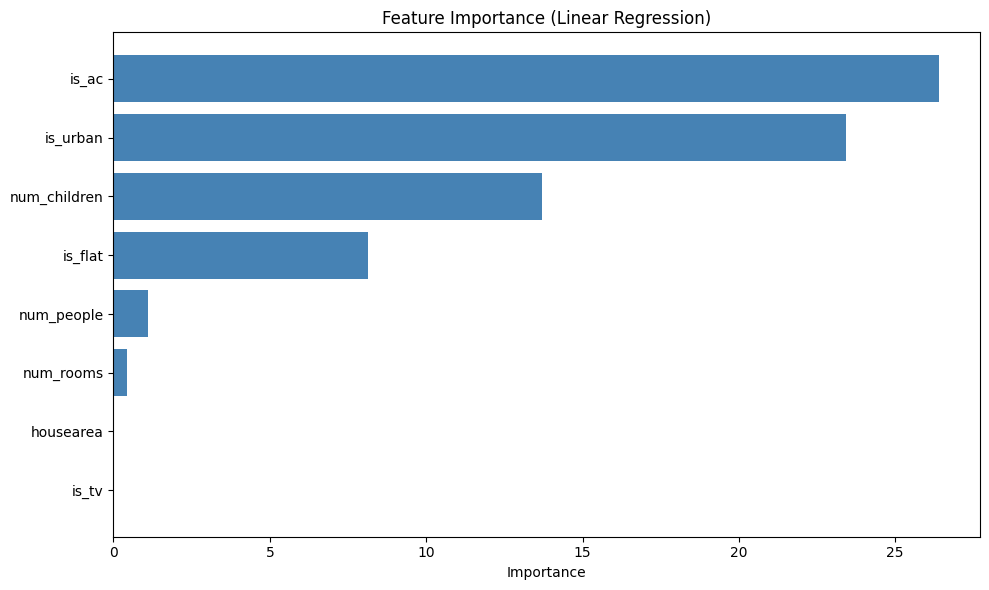


✅ Regression modeling completed!
        feature    importance
3         is_ac  2.639104e+01
7      is_urban  2.341393e+01
6  num_children  1.369174e+01
5       is_flat  8.131838e+00
1    num_people  1.111788e+00
0     num_rooms  4.302968e-01
2     housearea  5.713396e-03
4         is_tv  5.329071e-15


In [32]:
if best_reg_name == "Random Forest Regressor":
    importances = best_reg_model.feature_importances_
else:
    importances = np.abs(best_reg_model.coef_)

feature_importance = pd.DataFrame({
    'feature': regression_features,
    'importance': importances
}).sort_values('importance', ascending=False)

plt.figure(figsize=(10, 6))
plt.barh(feature_importance['feature'], feature_importance['importance'], color='steelblue')
plt.title(f'Feature Importance ({best_reg_name})')
plt.xlabel('Importance')
plt.gca().invert_yaxis()
plt.tight_layout()
plt.show()

print("\n✅ Regression modeling completed!")
print(feature_importance)

In [33]:
print("\n" + "="*70)
print("PART 3: CLASSIFICATION - ENERGY EFFICIENCY LABEL")
print("="*70)


PART 3: CLASSIFICATION - ENERGY EFFICIENCY LABEL


In [34]:
# The dataset has no ready-made efficiency label, so one is derived here:
# a household is "Efficient" (1) if its energy use per square meter is at or
# below the dataset median, otherwise "Inefficient" (0). Energy_per_SqM already
# normalizes for house size, which makes it a fair efficiency yardstick.
median_intensity = df_clean['Energy_per_SqM'].median()
df_clean = df_clean.copy()
df_clean['Efficiency_Label'] = (df_clean['Energy_per_SqM'] <= median_intensity).astype(int)

print(f"Median energy intensity: {median_intensity:.4f} kWh/sqm")
print(df_clean['Efficiency_Label'].value_counts().rename({1: 'Efficient', 0: 'Inefficient'}))

Median energy intensity: 0.1590 kWh/sqm
Efficiency_Label
Efficient      343
Inefficient    342
Name: count, dtype: int64


In [35]:
# Same raw household attributes as the regression model - not the energy-derived
# columns used to build the label itself, to avoid leaking the answer.
classification_features = ['num_rooms', 'num_people', 'housearea', 'is_ac', 'is_tv',
                            'is_flat', 'num_children', 'is_urban']

X_class = df_clean[classification_features]
y_class = df_clean['Efficiency_Label']

X_train_class, X_test_class, y_train_class, y_test_class = train_test_split(
    X_class, y_class, test_size=0.2, random_state=42, stratify=y_class
)

In [36]:
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train_class)
X_test_scaled = scaler.transform(X_test_class)

rf_model = RandomForestClassifier(n_estimators=200, random_state=42)
rf_model.fit(X_train_scaled, y_train_class)
y_pred_class = rf_model.predict(X_test_scaled)

In [37]:
print("U0001F4CA CLASSIFICATION RESULTS:")
print("\nClassification Report:")
print(classification_report(y_test_class, y_pred_class, target_names=['Inefficient', 'Efficient']))

U0001F4CA CLASSIFICATION RESULTS:

Classification Report:
              precision    recall  f1-score   support

 Inefficient       0.84      0.90      0.87        68
   Efficient       0.89      0.83      0.86        69

    accuracy                           0.86       137
   macro avg       0.86      0.86      0.86       137
weighted avg       0.86      0.86      0.86       137



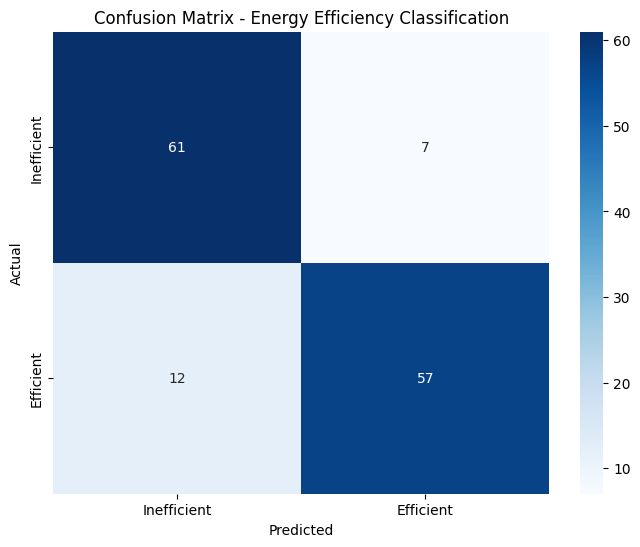

In [38]:
cm = confusion_matrix(y_test_class, y_pred_class)
plt.figure(figsize=(8, 6))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=['Inefficient', 'Efficient'],
            yticklabels=['Inefficient', 'Efficient'])
plt.title('Confusion Matrix - Energy Efficiency Classification')
plt.ylabel('Actual')
plt.xlabel('Predicted')
plt.show()

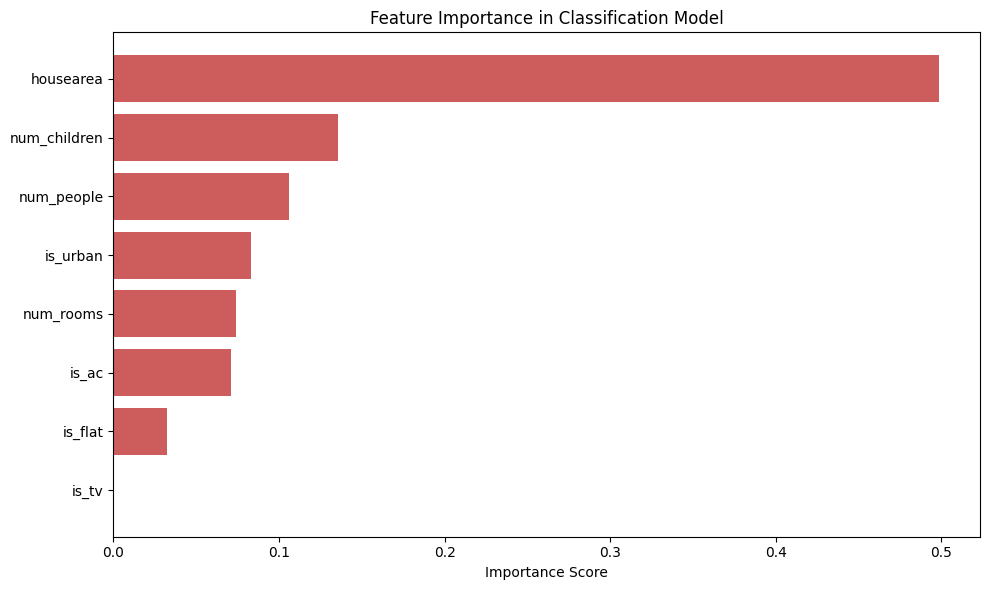


✅ Classification modeling completed!


In [39]:
feature_imp_class = pd.DataFrame({
    'feature': classification_features,
    'importance': rf_model.feature_importances_
}).sort_values('importance', ascending=False)

plt.figure(figsize=(10, 6))
plt.barh(feature_imp_class['feature'], feature_imp_class['importance'], color='indianred')
plt.title('Feature Importance in Classification Model')
plt.xlabel('Importance Score')
plt.gca().invert_yaxis()
plt.tight_layout()
plt.show()

print("\n✅ Classification modeling completed!")

In [40]:
print("\n" + "="*70)
print("PART 4: CLUSTERING - HOUSEHOLD CONSUMPTION SEGMENTS")
print("="*70)


PART 4: CLUSTERING - HOUSEHOLD CONSUMPTION SEGMENTS


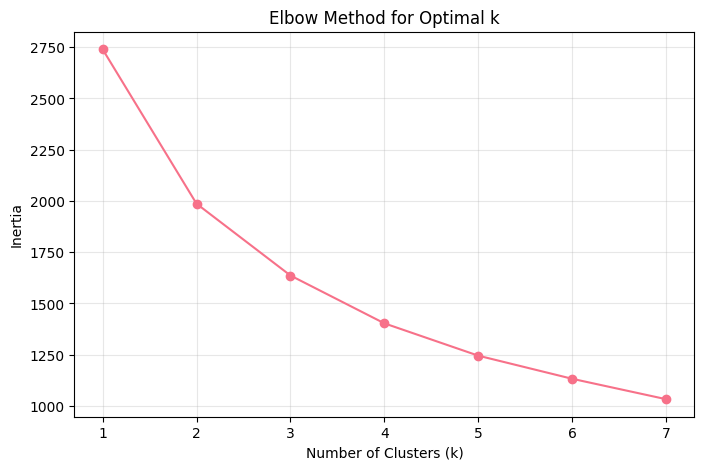

In [41]:
# Segment households by consumption behaviour rather than raw size, so a large
# efficient household and a small inefficient one aren't grouped together just
# because of floor area. Energy_per_Person and Energy_per_SqM already normalize
# for household size and area.
cluster_features = ['Energy_per_Person', 'Energy_per_SqM', 'num_rooms', 'housearea']
X_cluster = df_clean[cluster_features]

scaler_cluster = StandardScaler()
X_cluster_scaled = scaler_cluster.fit_transform(X_cluster)

# Elbow method to sanity-check the choice of k rather than picking one blindly.
inertias = []
k_range = range(1, 8)
for k in k_range:
    km = KMeans(n_clusters=k, random_state=42, n_init=10)
    km.fit(X_cluster_scaled)
    inertias.append(km.inertia_)

plt.figure(figsize=(8, 5))
plt.plot(list(k_range), inertias, marker='o')
plt.title('Elbow Method for Optimal k')
plt.xlabel('Number of Clusters (k)')
plt.ylabel('Inertia')
plt.grid(True, alpha=0.3)
plt.show()

In [42]:
kmeans = KMeans(n_clusters=3, random_state=42, n_init=10)
df_clean['Cluster'] = kmeans.fit_predict(X_cluster_scaled)

print(f"Cluster distribution:\n{df_clean['Cluster'].value_counts().sort_index()}")

Cluster distribution:
Cluster
0    232
1    292
2    161
Name: count, dtype: int64


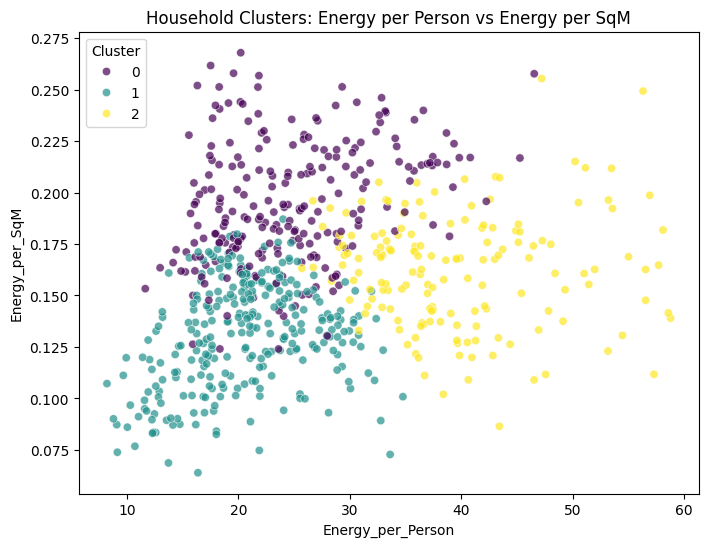

In [43]:
plt.figure(figsize=(8, 6))
sns.scatterplot(x='Energy_per_Person', y='Energy_per_SqM', hue='Cluster',
                data=df_clean, palette='viridis', alpha=0.7)
plt.title('Household Clusters: Energy per Person vs Energy per SqM')
plt.show()


Cluster profiles (average values):
         Energy_per_Person  Energy_per_SqM  num_rooms   housearea  \
Cluster                                                             
0                24.736290        0.195480   2.068966  670.491336   
1                20.659873        0.130843   2.020548  894.877363   
2                39.593318        0.162303   1.658385  854.139317   

         Total_Energy_kWh  
Cluster                    
0              130.254935  
1              116.708141  
2              137.255332  


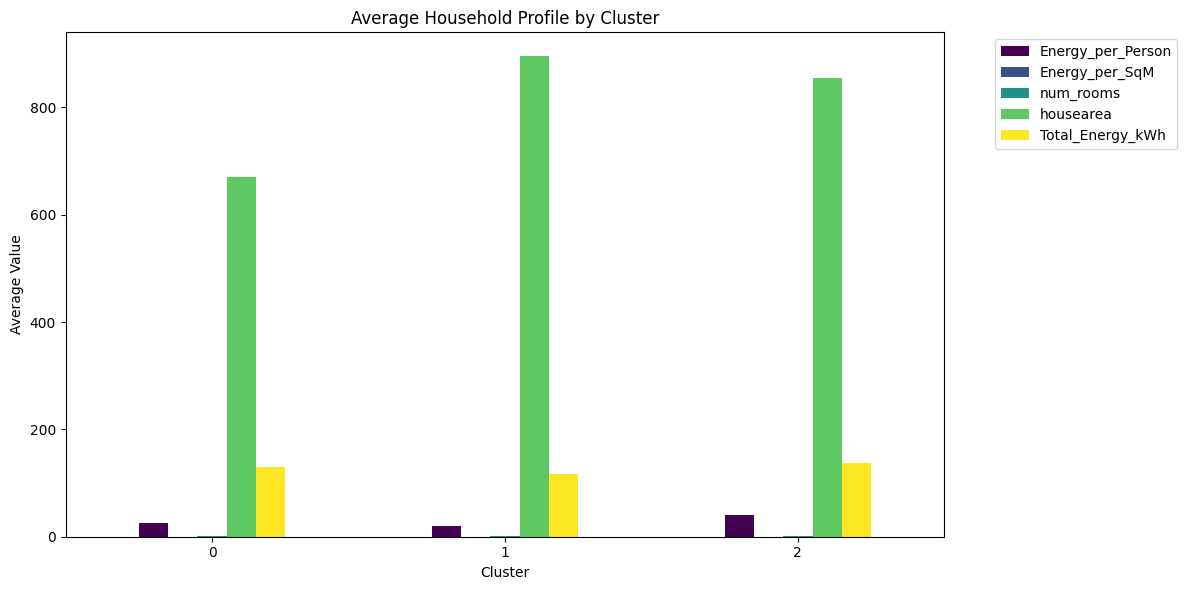


✅ Clustering analysis completed!


In [44]:
cluster_profile = df_clean.groupby('Cluster')[cluster_features + ['Total_Energy_kWh']].mean()
print("\nCluster profiles (average values):")
print(cluster_profile)

cluster_profile.plot(kind='bar', figsize=(12, 6), colormap='viridis')
plt.title('Average Household Profile by Cluster')
plt.ylabel('Average Value')
plt.xlabel('Cluster')
plt.xticks(rotation=0)
plt.legend(bbox_to_anchor=(1.05, 1), loc='upper left')
plt.tight_layout()
plt.show()

print("\n✅ Clustering analysis completed!")

In [45]:
print("\n" + "="*70)
print("U0001F4CB COMPREHENSIVE PROJECT REPORT SUMMARY")
print("="*70)

print(f"""
U0001F50D DATA OVERVIEW:
- Raw records: {df.shape[0]:,}
- Records after outlier removal: {df_clean.shape[0]:,}
- Household attributes used as model features: {len(regression_features)}

U0001F4CA REGRESSION MODEL PERFORMANCE ({best_reg_name}):
- R² Score: {r2:.4f}
- RMSE: {rmse:.2f} kWh
- Strongest predictor: {feature_importance.iloc[0]['feature']}

U0001F3AF CLASSIFICATION MODEL PERFORMANCE (Random Forest):
- Accuracy: {rf_model.score(X_test_scaled, y_test_class):.4f}
- Most important feature: {feature_imp_class.iloc[0]['feature']}

U0001F50D CLUSTERING INSIGHTS:
- Households segmented into {df_clean['Cluster'].nunique()} consumption profiles,
  based on normalized per-person and per-area energy use

U0001F4C8 KEY FINDINGS:
1. {feature_importance.iloc[0]['feature']} is the strongest predictor of total energy consumption.
2. Households can be classified as efficient/inefficient with {rf_model.score(X_test_scaled, y_test_class):.1%} accuracy using only structural attributes, before any energy data is collected.
3. Distinct household consumption segments emerge from clustering, useful for targeting efficiency programs.
""")

print("\n✅ PROJECT COMPLETED SUCCESSFULLY!")
print("✓ Data preprocessing and cleaning")
print("✓ Energy consumption regression")
print("✓ Energy efficiency classification")
print("✓ Household consumption clustering")


U0001F4CB COMPREHENSIVE PROJECT REPORT SUMMARY

U0001F50D DATA OVERVIEW:
- Raw records: 1,000
- Records after outlier removal: 685
- Household attributes used as model features: 8

U0001F4CA REGRESSION MODEL PERFORMANCE (Linear Regression):
- R² Score: 0.7377
- RMSE: 12.01 kWh
- Strongest predictor: is_ac

U0001F3AF CLASSIFICATION MODEL PERFORMANCE (Random Forest):
- Accuracy: 0.8613
- Most important feature: housearea

U0001F50D CLUSTERING INSIGHTS:
- Households segmented into 3 consumption profiles,
  based on normalized per-person and per-area energy use

U0001F4C8 KEY FINDINGS:
1. is_ac is the strongest predictor of total energy consumption.
2. Households can be classified as efficient/inefficient with 86.1% accuracy using only structural attributes, before any energy data is collected.
3. Distinct household consumption segments emerge from clustering, useful for targeting efficiency programs.


✅ PROJECT COMPLETED SUCCESSFULLY!
✓ Data preprocessing and cleaning
✓ Energy consumpti